# ADP 17회 실기 - 문항별 풀이 노트북

첨부 DataManim PDF의 **모든 세부 문항**을 원문과 함께 수록하고 독립적으로 작성한 예시 풀이입니다. 공식 정답지가 아닙니다. 데이터·그래프·평가표·가설검정 수치가 실행 결과로 포함됩니다.

**실행:** 압축 전체를 해제하고 이 노트북이 있는 `17회` 폴더에서 위에서 아래로 실행하세요. `data/`의 원자료를 읽으며 다운로드를 하지 않습니다. 재실행 결과는 `실행결과/`에 저장됩니다. Python 3.12 환경에서 실행 검증하며 Python 3.7용 의존성 안내도 별도로 제공합니다.

**평가 원칙:** 학습 구간에서만 대치·스케일링·변수 선택·리샘플링을 적합합니다. 모델·임계값 선택은 validation으로 하고 최종 test는 보류합니다. 시계열은 시간 순 분할을 사용합니다. 실행 시간은 기기와 반복 실행에 따라 달라집니다.

In [1]:
from pathlib import Path
import sys, platform, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score)
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
HERE = Path.cwd()
DATA = HERE / 'data'
assert DATA.is_dir(), '압축을 전체 해제한 뒤, 노트북이 있는 회차 폴더를 작업 위치로 실행하세요.'
OUT = HERE / '실행결과'
OUT.mkdir(exist_ok=True)
font_path = HERE.parent / '공통' / 'NanumGothic-Regular.ttf'
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
print('Python', platform.python_version())
import sklearn, scipy, statsmodels, imblearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__,
      'scipy', scipy.__version__, 'statsmodels', statsmodels.__version__, 'imblearn', imblearn.__version__)

def load(name):
    return pd.read_csv(DATA / name if (DATA / name).exists() else DATA / (name + ".gz"))

def ohe():
    return OneHotEncoder(handle_unknown='ignore', **({'sparse_output': False} if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else {'sparse': False}))

def reg_metrics(actual, predicted):
    a, b = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert a.shape == b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    mask = a != 0
    return {'MSE': mean_squared_error(a,b), 'RMSE': np.sqrt(mean_squared_error(a,b)),
            'MAE': mean_absolute_error(a,b), 'MAPE(%)': 100*np.mean(np.abs((a[mask]-b[mask])/a[mask])) if mask.any() else np.nan,
            'MAPE 제외 0개수': int((~mask).sum()), 'R2': r2_score(a,b)}

def class_metrics(actual, predicted, probability=None):
    a, b = np.asarray(actual), np.asarray(predicted)
    assert a.shape == b.shape
    result = {'Accuracy':accuracy_score(a,b), 'BalancedAccuracy':balanced_accuracy_score(a,b),
              'F1_macro':f1_score(a,b,average='macro',zero_division=0),
              'F1_weighted':f1_score(a,b,average='weighted',zero_division=0)}
    if probability is not None and set(np.unique(a)) == {0,1}:
        score = np.asarray(probability)
        score = score[:,1] if score.ndim == 2 else score
        result.update(ROC_AUC=roc_auc_score(a,score), AveragePrecision=average_precision_score(a,score))
    return result

def decision(p, alpha=.05):
    return '귀무가설 기각' if p < alpha else '귀무가설을 기각할 근거 부족'

def quality(frame):
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(), 'unique':frame.nunique()}))
    print('shape:', frame.shape, 'duplicate rows:', frame.duplicated().sum())
    display(frame.describe(include='all').T)

def plot_confusion(actual, prediction, labels=None, title='Confusion matrix'):
    order = np.unique(np.r_[actual,prediction]) if labels is None else labels
    matrix=confusion_matrix(actual,prediction,labels=order)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(order)),yticks=range(len(order)),xticklabels=order,yticklabels=order,
           xlabel='예측',ylabel='실제',title=title)
    for (i,j),value in np.ndenumerate(matrix):
        ax.text(j,i,int(value),ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()
    return pd.DataFrame(matrix,index=order,columns=order)

def median_predict_time(model, X, repeat=5):
    model.predict(X)
    elapsed=[]
    for _ in range(repeat):
        start=time.perf_counter();model.predict(X);elapsed.append(time.perf_counter()-start)
    return float(np.median(elapsed))

class IQRClipper(TransformerMixin, BaseEstimator):
    def __init__(self, factor=1.5): self.factor=factor
    def fit(self, X, y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lower_=q1-self.factor*(q3-q1);self.upper_=q3+self.factor*(q3-q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)

Python 3.12.14
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0 scipy 1.17.0 statsmodels 0.14.6 imblearn 0.14.2


## 1번 | 주택 가격

데이터 설명 : 집과 관련된 여러 수치들과 집의 가격, log1p 정규화된 price 컬럼 예측 하기

데이터 출처 : https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data?select=train.csv 일부 전처리

data Url : https://raw.githubusercontent.com/Datamanim/datarepo/main/adp/p3/problem1.csv

### 1-1

> 데이터 EDA 수행 후, 분석가 입장에서 의미있는 탐색
> 시각화 및 통계량 제시

**풀이 및 해석**

price는 이미 log1p 변환된 종속변수이므로 다시 로그 변환하지 않습니다. Id는 행 식별자라 예측 변수에서 제외합니다. 주택 면적·차고·건축 연도와 가격의 관계, 결측·상관·극단값을 확인합니다. 결측 중앙값은 이후 train에서만 추정합니다.

,dtype,missing,unique
Id,int64,0,1460
LotArea,int64,0,1073
LotFrontage,float64,259,110
YearBuilt,int64,0,112
1stFlrSF,int64,0,753
2ndFlrSF,int64,0,417
YearRemodAdd,int64,0,61
TotRmsAbvGrd,int64,0,12
KitchenAbvGr,int64,0,4
BedroomAbvGr,int64,0,8


shape: (1460, 13) duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.000000,365.750000,730.500000,1095.250000,1460.000000
LotArea,1460.0,10516.828082,9981.264932,1300.000000,7553.500000,9478.500000,11601.500000,215245.000000
LotFrontage,1201.0,70.049958,24.284752,21.000000,59.000000,69.000000,80.000000,313.000000
YearBuilt,1460.0,1971.267808,30.202904,1872.000000,1954.000000,1973.000000,2000.000000,2010.000000
1stFlrSF,1460.0,1162.626712,386.587738,334.000000,882.000000,1087.000000,1391.250000,4692.000000
2ndFlrSF,1460.0,346.992466,436.528436,0.000000,0.000000,0.000000,728.000000,2065.000000
YearRemodAdd,1460.0,1984.865753,20.645407,1950.000000,1967.000000,1994.000000,2004.000000,2010.000000
TotRmsAbvGrd,1460.0,6.517808,1.625393,2.000000,5.000000,6.000000,7.000000,14.000000
KitchenAbvGr,1460.0,1.046575,0.220338,0.000000,1.000000,1.000000,1.000000,3.000000
BedroomAbvGr,1460.0,2.866438,0.815778,0.000000,2.000000,3.000000,3.000000,8.000000


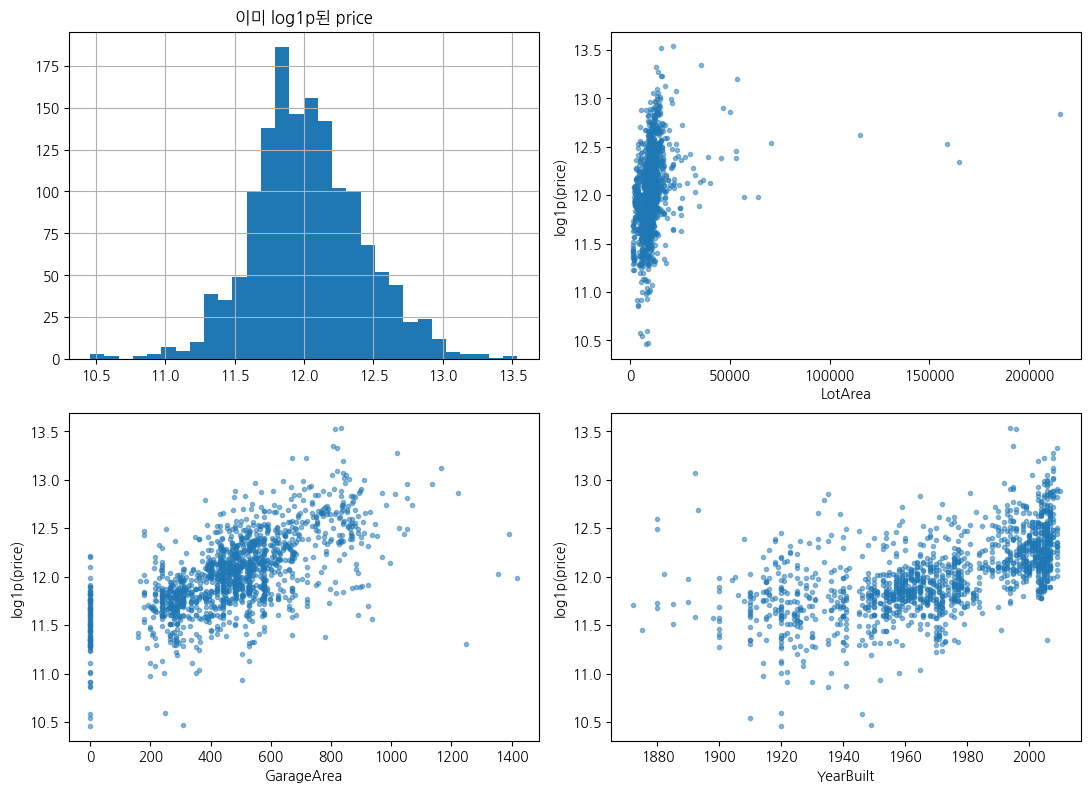

,price 상관
KitchenAbvGr,-0.147548
BedroomAbvGr,0.209043
LotArea,0.257320
2ndFlrSF,0.319300
LotFrontage,0.355879
TotRmsAbvGrd,0.534422
YearRemodAdd,0.565608
YearBuilt,0.586570
1stFlrSF,0.596981
GarageArea,0.650888


In [2]:
houses=load('problem1.csv');quality(houses)
fig,axs=plt.subplots(2,2,figsize=(11,8))
houses.price.hist(bins=30,ax=axs[0,0]);axs[0,0].set_title('이미 log1p된 price')
for ax,col in zip([axs[0,1],axs[1,0],axs[1,1]],['LotArea','GarageArea','YearBuilt']):
    ax.scatter(houses[col],houses.price,s=9,alpha=.5);ax.set(xlabel=col,ylabel='log1p(price)')
fig.tight_layout();plt.show()
display(houses.drop(columns='Id').corr().price.sort_values().to_frame('price 상관'))

### 1-2

> Train,Valid,Test set으로 분할 및 시각화 제시

**풀이 및 해석**

주택 표본의 별도 판매 시점이 제공되지 않아 IID 분할을 가정합니다. train/validation/test=60/20/20으로 나누고 가격 분포를 겹쳐 확인합니다. 확률적 분할이므로 이 예제 결과는 고정 시드에 대한 결과이며 실제 지역·시점 일반화는 별도 검증이 필요합니다.

,set,n,price_mean
0,train,876,12.029825
1,validation,292,12.033157
2,test,292,11.997654


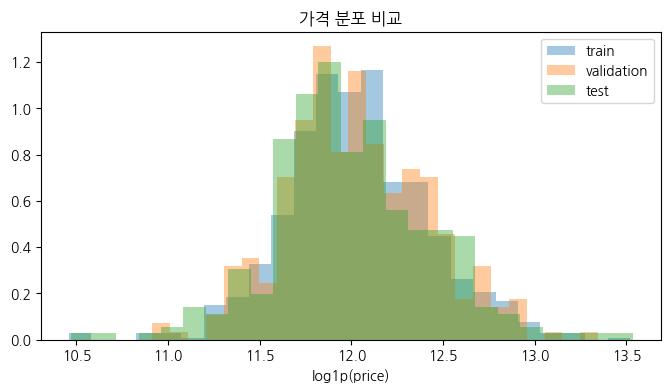

In [3]:
X=houses.drop(columns=['price','Id']);y=houses.price.to_numpy();ids=np.arange(len(houses))
train_valid,test_idx=train_test_split(ids,test_size=.2,random_state=SEED)
train_idx,valid_idx=train_test_split(train_valid,test_size=.25,random_state=SEED)
display(pd.DataFrame({'set':['train','validation','test'],'n':[len(train_idx),len(valid_idx),len(test_idx)],
                     'price_mean':[y[train_idx].mean(),y[valid_idx].mean(),y[test_idx].mean()]}))
fig,ax=plt.subplots(figsize=(8,4))
for name,index in [('train',train_idx),('validation',valid_idx),('test',test_idx)]:ax.hist(y[index],bins=25,density=True,alpha=.4,label=name)
ax.set(title='가격 분포 비교',xlabel='log1p(price)');ax.legend();plt.show()

### 1-3

> 2차 교호작용항 까지 고려한 회귀분석 수행 및 변수 선택 과정 제시

**풀이 및 해석**

원 변수와 서로 다른 두 변수의 2차 교호작용항을 생성합니다(제곱항은 제외). train의 중앙값·스케일을 재사용합니다. 주효과를 모두 유지한 상태에서 교호작용항의 최대 p값을 기준으로 후진 제거하여 강한 계층성을 지킵니다. 선택 이력·OLS 표·validation 성능을 제시합니다. 데이터에 따른 변수 선택 후 p값은 탐색적 결과로 해석합니다.

In [4]:
imputer=SimpleImputer(strategy='median').fit(X.iloc[train_idx])
scaler=StandardScaler().fit(imputer.transform(X.iloc[train_idx]))
poly=PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)
poly.fit(scaler.transform(imputer.transform(X.iloc[train_idx])))
all_design=poly.transform(scaler.transform(imputer.transform(X)))
names=poly.get_feature_names_out(X.columns);active=list(range(len(names)));main_count=X.shape[1];selection_log=[]
while True:
    fit=sm.OLS(y[train_idx],sm.add_constant(all_design[train_idx][:,active])).fit(cov_type='HC3')
    interaction_positions=[j for j,col in enumerate(active) if col>=main_count]
    if not interaction_positions:break
    pvalues=np.asarray(fit.pvalues)[1:];worst=max(interaction_positions,key=lambda j:pvalues[j])
    if pvalues[worst] <= .05:break
    selection_log.append({'removed':names[active[worst]],'p_HC3':pvalues[worst]});active.pop(worst)
ols_model=sm.OLS(y[train_idx],sm.add_constant(all_design[train_idx][:,active])).fit(cov_type='HC3')
display(pd.DataFrame(selection_log));display(pd.DataFrame({'term':['const']+list(names[active]),'coefficient':ols_model.params,'p_HC3':ols_model.pvalues}))
print('선택된 항 수:',len(active),'조건수:',ols_model.condition_number)
valid_pred=ols_model.predict(sm.add_constant(all_design[valid_idx][:,active],has_constant='add'))
display(pd.Series(reg_metrics(y[valid_idx],valid_pred),name='교호작용 OLS validation'))

,removed,p_HC3
0,1stFlrSF BedroomAbvGr,0.975392
1,KitchenAbvGr GarageArea,0.942457
2,TotRmsAbvGrd KitchenAbvGr,0.926619
3,LotArea BedroomAbvGr,0.927862
4,LotFrontage YearBuilt,0.869804
...,...,...
39,2ndFlrSF BedroomAbvGr,0.225341
40,LotFrontage GarageCars,0.071588
41,LotArea 2ndFlrSF,0.055110
42,YearBuilt 1stFlrSF,0.156681


,term,coefficient,p_HC3
0,const,12.013181,0.000000e+00
1,LotArea,0.099189,2.089210e-03
2,LotFrontage,0.006850,4.219760e-01
3,YearBuilt,0.105211,1.918166e-27
4,1stFlrSF,0.163340,1.255215e-19
...,...,...,...
18,2ndFlrSF GarageCars,0.037336,1.197931e-03
19,YearRemodAdd KitchenAbvGr,0.016933,2.949200e-03
20,TotRmsAbvGrd BedroomAbvGr,-0.008936,4.135834e-02
21,BedroomAbvGr GarageCars,-0.022537,1.047657e-03


선택된 항 수: 22 조건수: 8.660964844148147


MSE            0.028488
RMSE           0.168784
MAE            0.122742
MAPE(%)        1.023840
MAPE 제외 0개수    0.000000
R2             0.814911
Name: 교호작용 OLS validation, dtype: float64

### 1-4

> 벌점, 앙상블을 포함하여 모형에 적합한 기계학습 모델 3가지를 제시하라
> (평가지표는 MSE, MAPE, R2 모두 확인할 것)

**풀이 및 해석**

벌점 모델 RidgeCV, 앙상블 Random Forest·Gradient Boosting을 같은 분할에서 비교합니다. Ridge의 alpha는 train 내부 5-fold CV로 정합니다. MSE·MAPE·R²는 문제에서 지정한 log1p(price) 척도에서 계산하고, 해석을 돕기 위해 선택 모델의 원가격 RMSE도 제시합니다. validation MSE로 최종 모델을 정하고 test에는 선택된 모델만 평가합니다.

In [5]:
from sklearn.linear_model import Ridge
# 후기의 Hyperparameter 조절 요구를 반영. 전처리도 각 CV train에서 적합.
REPO=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'src/MachineLearning/Optimization/grid_search.py').exists())
sys.path.insert(0,str(REPO))
from src.MachineLearning.Optimization.grid_search import run_grid_search
reg_candidates={'Ridge':(Ridge(), {'model__alpha':[.1,1.,10.]}),
                'RandomForest':(RandomForestRegressor(n_estimators=80,random_state=SEED,n_jobs=1), {'model__max_depth':[4,8,None]}),
                'GradientBoosting':(GradientBoostingRegressor(n_estimators=80,random_state=SEED), {'model__max_depth':[1,2,3]})}
reg_models={};rows=[]
for name,(est,space) in reg_candidates.items():
    pipeline=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',est)])
    start=time.perf_counter()
    optimized=run_grid_search(X.iloc[train_idx],y[train_idx],pipeline,task='regression',overrides={'cv':3,'scoring':'neg_mean_squared_error','search_space':space})
    model=optimized.model;elapsed=time.perf_counter()-start
    rows.append({'model':name,**reg_metrics(y[valid_idx],model.predict(X.iloc[valid_idx])),'CV_MSE':-optimized.best_score,'best_params':str(optimized.best_params),'fit_seconds':elapsed});reg_models[name]=model
validation=pd.DataFrame(rows).set_index('model');display(validation)
best_name=validation.MSE.idxmin()
# validation에서 모델 종류 선정 후 train+validation에 재적합. test로 재튜닝하지 않음.
selected_model=clone(reg_models[best_name]).fit(X.iloc[np.r_[train_idx,valid_idx]],y[np.r_[train_idx,valid_idx]])
test_prediction=selected_model.predict(X.iloc[test_idx]);print('validation MSE 기준 선택:',best_name)
display(pd.Series(reg_metrics(y[test_idx],test_prediction),name='최종 test, log1p 척도'))
original_actual=np.expm1(y[test_idx]);original_prediction=np.expm1(test_prediction)
display(pd.Series(reg_metrics(original_actual,original_prediction),name='보조: 원가격 척도'))
validation.to_csv(OUT/'주택_모델_validation비교.csv')
print('후기 RMAE는 정의가 불명확하므로 원문 요구 MSE/MAE/MAPE/R²로 보고. log1p price를 중복 변환하지 않음.')


,MSE,RMSE,MAE,MAPE(%),MAPE 제외 0개수,R2,CV_MSE,best_params,fit_seconds
model,,,,,,,,,
Ridge,0.030955,0.175941,0.129051,1.076832,0,0.798881,0.036612,{'model__alpha': 10.0},0.041537
RandomForest,0.031261,0.176808,0.122260,1.020472,0,0.796895,0.032777,{'model__max_depth': None},1.475506
GradientBoosting,0.027059,0.164495,0.118500,0.989549,0,0.824198,0.029811,{'model__max_depth': 3},0.731317


validation MSE 기준 선택: GradientBoosting


MSE            0.033634
RMSE           0.183396
MAE            0.127099
MAPE(%)        1.072612
MAPE 제외 0개수    0.000000
R2             0.819763
Name: 최종 test, log1p 척도, dtype: float64

MSE            1.121494e+09
RMSE           3.348871e+04
MAE            2.186864e+04
MAPE(%)        1.353650e+01
MAPE 제외 0개수    0.000000e+00
R2             8.537880e-01
Name: 보조: 원가격 척도, dtype: float64

후기 RMAE는 정의가 불명확하므로 원문 요구 MSE/MAE/MAPE/R²로 보고. log1p price를 중복 변환하지 않음.


## 2번 | 코로나19 국가별 데이터

데이터 설명 : 코로나19에 대한 나라별 데이터로 모델링 진행

데이터 출처 : https://www.kaggle.com/imdevskp/corona-virus-report 일부 후처리

data Url : https://raw.githubusercontent.com/Datamanim/datarepo/main/adp/p3/problem2.csv

location : 지역명 / date : 일자 / total_cases : 누적 확인자 / total_deaths : 누적 사망자 / new_tests : 검사자 / population : 인구 / new_vaccinations : 백신 접종자

### 2-1

> 마지막 일자를 기준으로 인구 대비 확진자 비율이 높은 상위 5개 국가를 구하여라
> 상위 5개 국가별로 누적 확진자, 일일 확진자, 누적 사망자, 일일 사망자, 그래프, 범례를 이용해서 가독성 있게 만들어라

**풀이 및 해석**

비국가 집계 지역을 제외하고 자료의 마지막 공통 일자에 실제로 관측된 국가만 비교합니다. 누적값은 국가 내 과거 자료로만 전방 대치하며, 최초 관측 이전을 뒤에서 채우지 않습니다. 일일 확진·사망은 정렬된 누적값의 차분으로 구합니다. 음수 차분은 소급 집계 수정일 수 있어 그래프에는 그대로 표시하고 최근 위험지수에서는 별도로 0으로 제한합니다.

,location,date,population,total_cases,case_ratio
83449,Montenegro,2021-11-30,628051.0,157376.0,0.250578
108918,Seychelles,2021-11-30,98910.0,23417.0,0.236751
3231,Andorra,2021-11-30,77354.0,17115.0,0.221256
111048,Slovakia,2021-11-30,5460726.0,1170200.0,0.214294
46158,Georgia,2021-11-30,3979773.0,845643.0,0.212485


비교 기준일: 2021-11-30 국가 수: 194


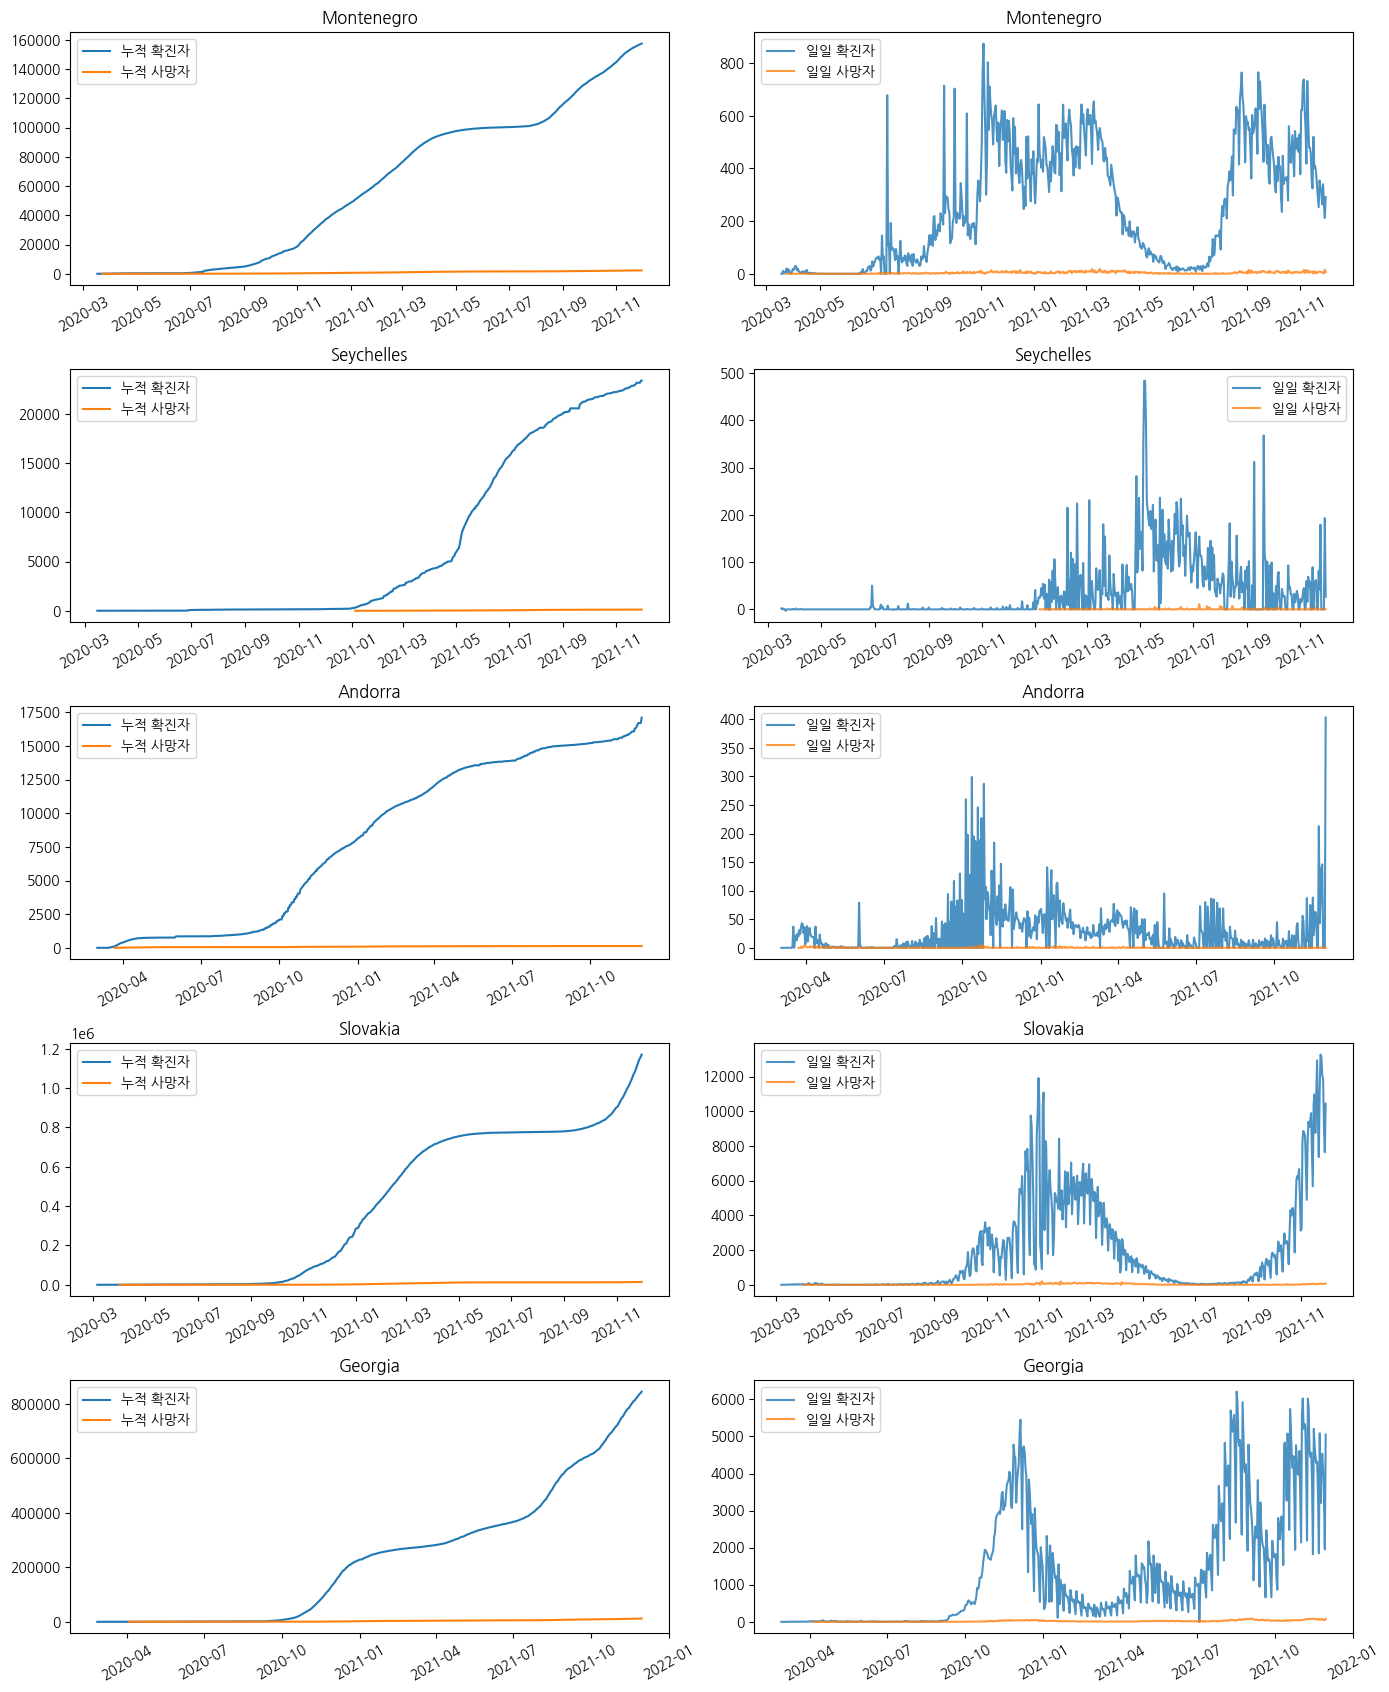

In [6]:
covid=load('problem2.csv');covid['date']=pd.to_datetime(covid.date)
aggregates={'World','Africa','Asia','Europe','European Union','North America','South America','Oceania','International','High income','Low income','Lower middle income','Upper middle income'}
covid=covid[~covid.location.isin(aggregates)].sort_values(['location','date']).copy()
assert not covid.duplicated(['location','date']).any()
for col in ['total_cases','total_deaths','population']:
    covid[col]=covid.groupby('location')[col].ffill()
covid['daily_cases']=covid.groupby('location').total_cases.diff()
covid['daily_deaths']=covid.groupby('location').total_deaths.diff()
last_date=covid.date.max()
latest=covid[covid.date==last_date].dropna(subset=['population','total_cases']).copy()
latest=latest[latest.population>0];latest['case_ratio']=latest.total_cases/latest.population
ranking=latest.nlargest(5,'case_ratio')[['location','date','population','total_cases','case_ratio']]
display(ranking);print('비교 기준일:',last_date.date(),'국가 수:',len(latest))
fig,axs=plt.subplots(5,2,figsize=(14,17))
for i,country in enumerate(ranking.location):
    z=covid[covid.location==country]
    axs[i,0].plot(z.date,z.total_cases,label='누적 확진자');axs[i,0].plot(z.date,z.total_deaths,label='누적 사망자')
    axs[i,1].plot(z.date,z.daily_cases,label='일일 확진자',alpha=.8);axs[i,1].plot(z.date,z.daily_deaths,label='일일 사망자',alpha=.8)
    for ax in axs[i]:ax.set_title(country);ax.legend();ax.tick_params(axis='x',rotation=30)
fig.tight_layout();plt.show()

### 2-2

> 코로나 위험지수를 직접 만들고 그 위험지수에 대한 설명을 적고 위험지수가 높은 국가들 10개를 선정해서 시각화

**풀이 및 해석**

교육용 상대 위험지수로 최근 7일 평균 신규 확진자/10만 명의 국가 간 백분위 70%와 최근 7일 평균 신규 사망자/10만 명의 백분위 30%를 결합합니다. 최근 발생과 중증 부담을 구분하고 인구 규모를 보정합니다. 가중치는 분석 가정이며 임상·정책 기준이 아닙니다. 결측을 위험 0으로 간주하지 않고 계산 불가능한 국가는 제외·보고합니다.

,location,risk_index,cases_per100k,deaths_per100k
111048,Slovakia,98.870968,202.735994,1.132764
31979,Czechia,98.010753,175.795539,1.019023
29826,Croatia,96.881720,110.501341,1.613490
55429,Hungary,96.612903,105.121457,1.746760
46158,Georgia,95.591398,94.983881,1.575826
12845,Belgium,95.053763,160.095619,0.380712
111716,Slovenia,94.408602,105.978526,0.831554
8364,Austria,94.193548,126.478827,0.597142
87717,Netherlands,93.440860,129.194624,0.306127
3231,Andorra,92.258065,142.757416,0.184680


자료 부족 제외 국가: 8


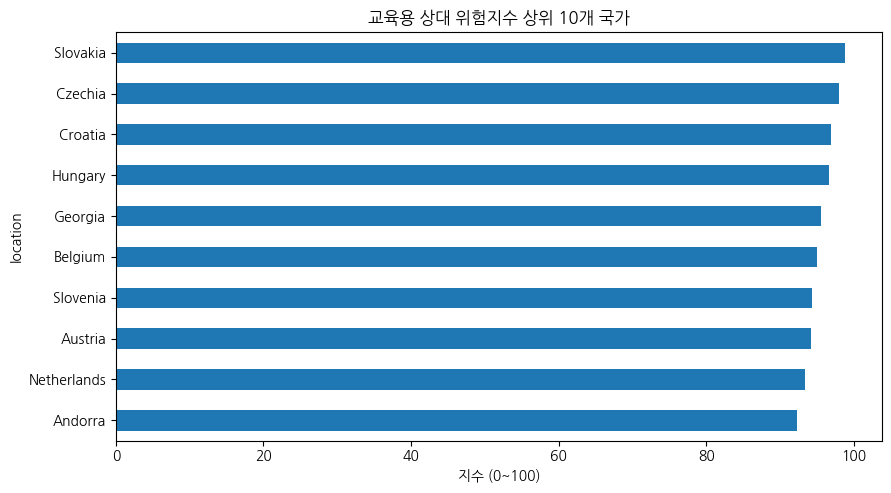

In [7]:
for source,out in [('daily_cases','case7'),('daily_deaths','death7')]:
    covid[out]=covid.groupby('location')[source].transform(lambda s:s.clip(lower=0).rolling(7,min_periods=7).mean())
risk=covid[covid.date==last_date].copy();risk['cases_per100k']=1e5*risk.case7/risk.population
risk['deaths_per100k']=1e5*risk.death7/risk.population
eligible=risk.dropna(subset=['cases_per100k','deaths_per100k']);eligible=eligible[eligible.population>0].copy()
eligible['risk_index']=100*(.7*eligible.cases_per100k.rank(pct=True)+.3*eligible.deaths_per100k.rank(pct=True))
top10=eligible.nlargest(10,'risk_index')[['location','risk_index','cases_per100k','deaths_per100k']]
display(top10);print('자료 부족 제외 국가:',len(risk)-len(eligible))
fig,ax=plt.subplots(figsize=(9,5));top10.sort_values('risk_index').plot.barh(x='location',y='risk_index',ax=ax,legend=False)
ax.set(title='교육용 상대 위험지수 상위 10개 국가',xlabel='지수 (0~100)');fig.tight_layout();plt.show()
top10.to_csv(OUT/'코로나_위험지수_상위10.csv',index=False)

### 2-3

> 한국의 코로나 신규 확진자 예측해라(선형 시계열모델 + 비선형시계열 각각 한개씩 만들어라)
> 선형시계열 - arma 비선형 시계열 - arima

**풀이 및 해석**

원문의 ARIMA 비선형 분류는 잘못된 표현입니다. ARMA와 ARIMA는 모두 선형 모형이며 차이는 차분(d) 여부입니다. 원문에 명시된 ARMA(2,0,1)·ARIMA(2,1,1)를 모두 구현하고, 실제 비선형 모형으로 lag 특성 기반 Gradient Boosting을 추가합니다. 마지막 30일을 보류하고 비선형 모형도 재귀적으로 30일을 예측하여 test의 실제 lag를 학습·예측 입력으로 사용하지 않습니다.

train 종료: 2021-10-31 00:00:00 test 시작: 2021-11-01 00:00:00 train ADF p: 0.9445516207492677


/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,MSE,RMSE,MAE,MAPE(%),MAPE 제외 0개수,R2
ARMA,3.344479e+06,1828.791734,1562.336115,49.538771,0.0,-4.027774
ARIMA,1.749425e+06,1322.658298,1063.474393,32.535705,0.0,-1.629920
GradientBoosting,1.849899e+06,1360.109996,1134.115194,35.647360,0.0,-1.780963


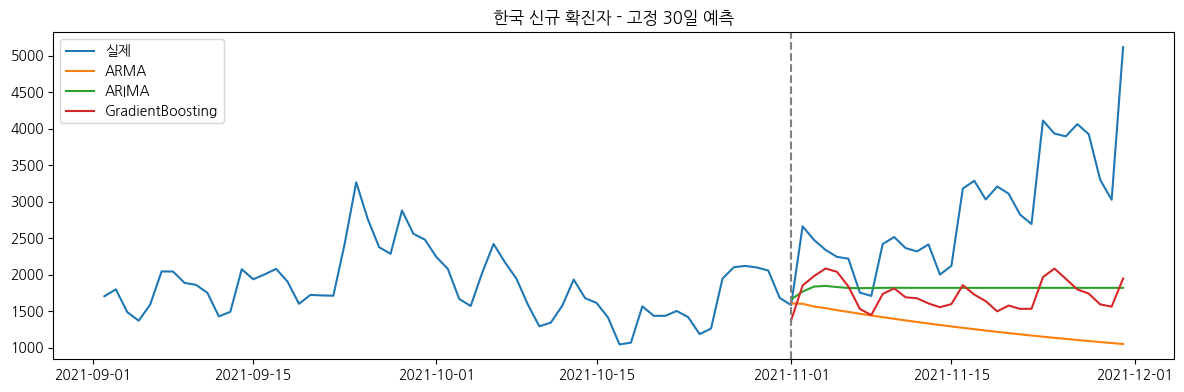

In [8]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
korea=covid[covid.location.isin(['South Korea','Korea, South'])].set_index('date').sort_index()
assert len(korea)>60
cumulative=korea.total_cases.asfreq('D').ffill();series=cumulative.diff().dropna().clip(lower=0)
train_series=series.iloc[:-30];future=series.iloc[-30:]
print('train 종료:',train_series.index[-1],'test 시작:',future.index[0],'train ADF p:',adfuller(train_series)[1])
forecasts={}
for name,order in [('ARMA',(2,0,1)),('ARIMA',(2,1,1))]:
    model=ARIMA(train_series,order=order).fit(method_kwargs={'maxiter':150})
    forecasts[name]=np.maximum(np.asarray(model.forecast(len(future))),0)
lags=[1,2,3,7,14,28]
lag_frame=pd.DataFrame({'y':train_series})
for lag in lags:lag_frame['lag_'+str(lag)]=train_series.shift(lag)
lag_frame['weekday']=lag_frame.index.dayofweek;lag_frame=lag_frame.dropna()
nonlinear=GradientBoostingRegressor(n_estimators=150,max_depth=2,random_state=SEED)
nonlinear.fit(lag_frame.drop(columns='y'),lag_frame.y)
history=train_series.tolist();recursive=[]
for date in future.index:
    row=pd.DataFrame([[history[-lag] for lag in lags]+[date.dayofweek]],columns=lag_frame.drop(columns='y').columns)
    value=max(float(nonlinear.predict(row)[0]),0);history.append(value);recursive.append(value)
forecasts['GradientBoosting']=np.asarray(recursive)
display(pd.DataFrame({name:reg_metrics(future.to_numpy(),pred) for name,pred in forecasts.items()}).T)
fig,ax=plt.subplots(figsize=(12,4));ax.plot(series.iloc[-90:].index,series.iloc[-90:].values,label='실제')
for name,pred in forecasts.items():ax.plot(future.index,pred,label=name)
ax.axvline(future.index[0],color='gray',ls='--');ax.set(title='한국 신규 확진자 - 고정 30일 예측');ax.legend();fig.tight_layout();plt.show()

## 3번 | 설문조사 데이터

데이터 출처 : 자체 제작

data Url : https://raw.githubusercontent.com/Datamanim/datarepo/main/adp/p3/problem3.csv

데이터 설명 : A ~ D까지의 그룹에게 각각 같은 설문조사를 하여 1-1,1-2,1-3…5-1,5-4 인 설문지를 푼 것이다. 문항은 영역별로 나뉘어 있고, 영역은 크게 5개이다(1~5). 각 영역의 세부문항은 4개씩 존재한다 (1-1,1-2,1-3,1-4 ~).

이 때 중간에 반대 문항이 들어가 있다. 예를 들어 1-1 문제가 “나는 시간약속을 잘 지킨다.”라는 문제라면 1-3의 문제는 “나는 시간약속을 잘 지키지 않는다.” 라는 역문제로 구성 되어있다. 각 영역의 3번문항의 1번문항의 역문제이다. 모든 답변은 5점 척도이다. 문제를 풀기전 모든 역문항의 경우 점수를 변환(6점을 빼서) 작업이 필요하다.

### 3-1

> 역문항을 변환 한 후 각 그룹(A~D)의 영역(Q1~Q5)별 응답의 평균, 표준편차, 왜도, 첨도를 구하라. (각 통계량 별로 4x5 dataframe 생성)

**풀이 및 해석**

5점 척도 역문항은 6−원점수로 변환합니다. “6점을 빼서”라는 원문 표현을 그대로 수행하면 음수가 되어 잘못입니다. Qk-3만 변환하고, 개인별 영역 4문항 평균을 영역 점수로 정의한 뒤 그룹별 평균·표본 표준편차·왜도·초과첨도를 계산하여 네 개의 4×5 표를 만듭니다. 영역 안의 모든 문항 응답을 펼치는 다른 해석도 보조 표로 제시합니다.

In [9]:
survey=load('problem3.csv');items=[c for c in survey if c.startswith('Q')]
assert survey[items].isin([1,2,3,4,5]).all().all()
corrected=survey.copy()
for domain in range(1,6):corrected['Q%d-3'%domain]=6-corrected['Q%d-3'%domain]
domains=pd.DataFrame({'group':corrected.group})
for domain in range(1,6):domains['Q'+str(domain)]=corrected[['Q%d-%d'%(domain,item) for item in range(1,5)]].mean(axis=1)
summary_tables={}
for statistic in ['mean','std','skew','kurt']:
    if statistic=='kurt':result=domains.groupby('group')[[f'Q{k}' for k in range(1,6)]].agg(lambda s:s.kurt())
    else:result=domains.groupby('group')[[f'Q{k}' for k in range(1,6)]].agg(statistic)
    assert result.shape==(4,5);summary_tables[statistic]=result
    print(statistic);display(result);result.to_csv(OUT/('설문_영역점수_'+statistic+'.csv'))
flat_tables={}
for statistic in ['mean','std','skew','kurt']:
    frame=pd.DataFrame(index=sorted(corrected.group.unique()),columns=[f'Q{k}' for k in range(1,6)],dtype=float)
    for group,g in corrected.groupby('group'):
        for domain in range(1,6):
            values=pd.Series(g[['Q%d-%d'%(domain,item) for item in range(1,5)]].to_numpy().ravel())
            frame.loc[group,'Q'+str(domain)]=getattr(values,statistic)()
    flat_tables[statistic]=frame
print('보조 해석: 문항 응답 전체를 펼친 표준편차');display(flat_tables['std'])

mean


,Q1,Q2,Q3,Q4,Q5
group,,,,,
A,3.016,3.058,2.992,3.043,3.088
B,3.042,3.048,3.050,3.041,2.983
C,3.030,3.063,3.023,3.014,2.987
D,2.991,3.091,3.034,3.080,2.989


std


,Q1,Q2,Q3,Q4,Q5
group,,,,,
A,0.650335,0.645992,0.610678,0.638775,0.649958
B,0.600983,0.635461,0.656295,0.650200,0.607815
C,0.616946,0.602272,0.591286,0.592629,0.600854
D,0.614148,0.614802,0.589691,0.692835,0.644819


skew


,Q1,Q2,Q3,Q4,Q5
group,,,,,
A,-0.096957,-0.060131,-0.059263,0.061382,-0.199553
B,-0.040337,-0.293950,-0.135071,-0.354112,0.176160
C,-0.169801,-0.003913,-0.018859,-0.182083,-0.048578
D,-0.220293,-0.035788,-0.106694,-0.196309,0.094299


kurt


,Q1,Q2,Q3,Q4,Q5
group,,,,,
A,-0.542800,-0.343675,-0.459040,-0.582634,-0.156818
B,-0.229331,-0.116011,0.045245,-0.132512,0.112269
C,-0.446177,-0.112603,0.011954,-0.039945,-0.290300
D,-0.357115,-0.340848,-0.277945,-0.708606,0.042568


보조 해석: 문항 응답 전체를 펼친 표준편차


,Q1,Q2,Q3,Q4,Q5
A,1.263860,1.236999,1.268679,1.255678,1.256119
B,1.242489,1.266215,1.238965,1.240507,1.272136
C,1.243642,1.256427,1.248210,1.283531,1.260325
D,1.264325,1.249913,1.255556,1.268546,1.250777


### 3-2

> 그룹별로 Q1-1문항의 차이가 존재하는지 anova분석을 시행하라

**풀이 및 해석**

H0: A~D의 Q1-1 평균이 모두 같다. H1: 적어도 하나의 그룹 평균이 다르다. 정규성·등분산을 진단하고 고전 ANOVA와 Welch 결과를 함께 보고합니다. 설문 응답이 순서형임을 고려하여 Kruskal–Wallis를 보조로 제시하며, 이것은 평균 검정과 가설이 동일하지 않습니다. 사후검정은 전체 검정이 유의할 때 수행합니다.

In [10]:
groups=[g['Q1-1'].to_numpy() for _,g in corrected.groupby('group')]
F,pvalue=stats.f_oneway(*groups);welch=anova_oneway(groups,use_var='unequal')
lev=stats.levene(*groups,center='median');kw=stats.kruskal(*groups)
display(pd.DataFrame({'test':['고전 ANOVA','Welch ANOVA','Levene','Kruskal-Wallis'],
                     'statistic':[F,welch.statistic,lev.statistic,kw.statistic],
                     'p_value':[pvalue,welch.pvalue,lev.pvalue,kw.pvalue]}))
print('고전 ANOVA:',decision(pvalue),'Welch:',decision(welch.pvalue))
if pvalue<.05:
    from statsmodels.stats.multicomp import pairwise_tukeyhsd
    print(pairwise_tukeyhsd(corrected['Q1-1'],corrected.group,alpha=.05))

,test,statistic,p_value
0,고전 ANOVA,1.537517,0.203181
1,Welch ANOVA,1.583062,0.192410
2,Levene,0.247181,0.863369
3,Kruskal-Wallis,4.567127,0.206380


고전 ANOVA: 귀무가설을 기각할 근거 부족 Welch: 귀무가설을 기각할 근거 부족


### 3-3

> 탐색적 요인분석을 수행하고 결과를 시각화 하라

**풀이 및 해석**

역채점 후 20개 문항의 상관행렬을 사용합니다. Bartlett 구형성·KMO로 요인분석 적합성을 진단하고, 고유값 스크리 및 평행분석으로 요인 수를 정합니다. principal-axis 요인분석과 varimax 회전을 적용하여 적재량·공통성과 설명 분산을 시각화합니다. Likert 문항의 Pearson 상관 기반 EFA는 근사 분석이며 순서형 자료에는 다분상관 기반 분석을 추가 검토할 수 있습니다.

KMO: 0.4906789809649266 Bartlett chi2: 212.8371202728898 df: 190 p: 0.12271947500297231
평행분석이 지지한 요인 수: 0
공통요인 지지가 없어 1요인 적합은 탐색적 예시로만 제시합니다.
실제 적합 요인 수: 1


/root/.local/lib/python3.12/site-packages/statsmodels/multivariate/factor_rotation/_gpa_rotation.py:101: RuntimeWarning: divide by zero encountered in log10
  table.append([i_try, f, np.log10(s), al])


,Factor1
Q1-1,-0.009745
Q1-2,0.058590
Q1-3,-0.018345
Q1-4,0.073608
Q2-1,0.088704
Q2-2,0.032713
Q2-3,0.179406
Q2-4,-0.041612
Q3-1,0.158866
Q3-2,-0.094620


,communality
Q1-1,0.000095
Q1-2,0.003433
Q1-3,0.000337
Q1-4,0.005418
Q2-1,0.007868
Q2-2,0.001070
Q2-3,0.032187
Q2-4,0.001732
Q3-1,0.025239
Q3-2,0.008953


회전 요인별 전체 문항 분산 비율: [0.01888544]


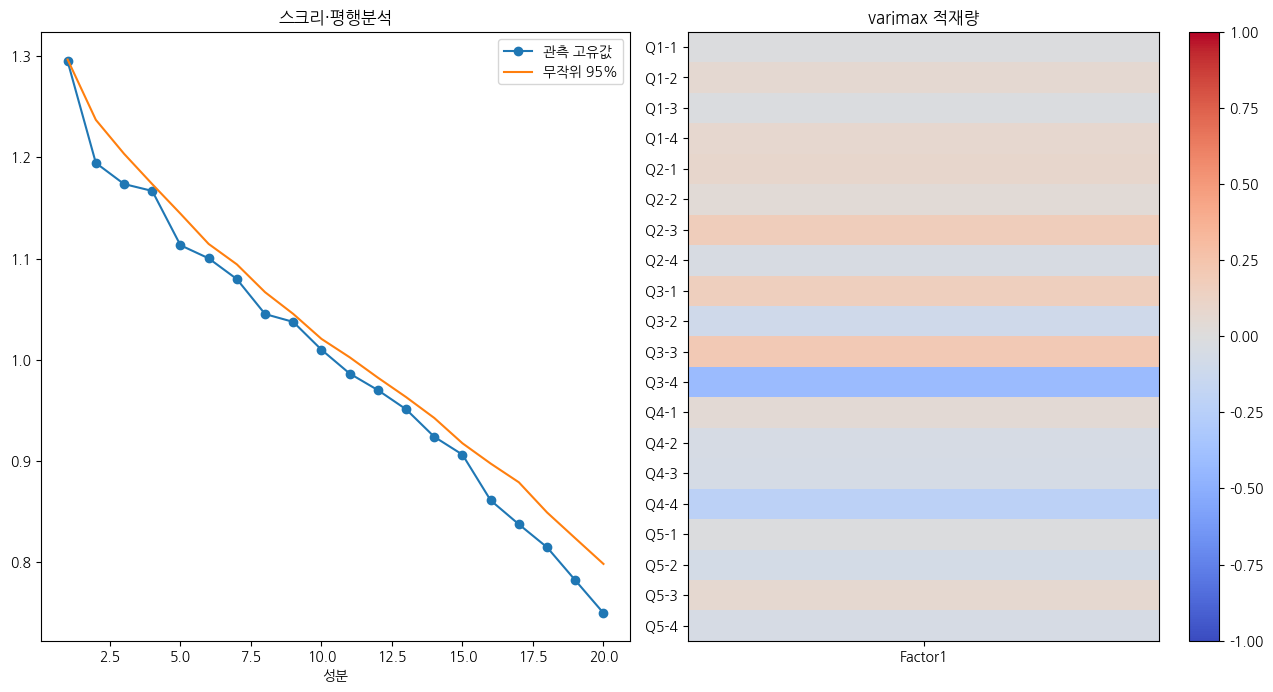

In [11]:
from statsmodels.multivariate.factor import Factor
responses=corrected[items].to_numpy(dtype=float)
R=np.corrcoef(responses,rowvar=False);n,pdim=responses.shape
inverse=np.linalg.pinv(R);partial=-inverse/np.sqrt(np.outer(np.diag(inverse),np.diag(inverse)))
np.fill_diagonal(partial,0);R_off=R.copy();np.fill_diagonal(R_off,0)
kmo=(R_off**2).sum()/((R_off**2).sum()+(partial**2).sum())
sign,logdet=np.linalg.slogdet(R)
assert sign>0
bartlett=-(n-1-(2*pdim+5)/6)*logdet;df_b=pdim*(pdim-1)//2
print('KMO:',kmo,'Bartlett chi2:',bartlett,'df:',df_b,'p:',stats.chi2.sf(bartlett,df_b))
eigenvalues=np.linalg.eigvalsh(R)[::-1];rng=np.random.RandomState(SEED)
parallel=np.array([np.linalg.eigvalsh(np.corrcoef(rng.normal(size=(n,pdim)),rowvar=False))[::-1] for _ in range(100)])
benchmark=np.percentile(parallel,95,axis=0)
# Keep the leading consecutive components exceeding the null benchmark.
exceed=eigenvalues>benchmark;factors=0
for flag in exceed:
    if not flag:break
    factors+=1
supported_factors=factors
factors=max(1,min(factors,pdim-1));print('평행분석이 지지한 요인 수:',supported_factors)
if supported_factors==0:print('공통요인 지지가 없어 1요인 적합은 탐색적 예시로만 제시합니다.')
print('실제 적합 요인 수:',factors)
result=Factor(corr=R,n_factor=factors,nobs=n,method='pa').fit();result.rotate('varimax')
loadings=np.asarray(result.loadings)
loading_table=pd.DataFrame(loadings,index=items,columns=['Factor'+str(i+1) for i in range(factors)])
display(loading_table);display(pd.DataFrame({'communality':np.sum(loadings**2,axis=1)},index=items))
print('회전 요인별 전체 문항 분산 비율:',np.sum(loadings**2,axis=0)/pdim)
fig,axs=plt.subplots(1,2,figsize=(13,7))
axs[0].plot(range(1,pdim+1),eigenvalues,marker='o',label='관측 고유값');axs[0].plot(range(1,pdim+1),benchmark,label='무작위 95%');axs[0].legend();axs[0].set(xlabel='성분',title='스크리·평행분석')
im=axs[1].imshow(loadings,cmap='coolwarm',vmin=-1,vmax=1,aspect='auto');axs[1].set(yticks=range(pdim),yticklabels=items,xticks=range(factors),xticklabels=loading_table.columns,title='varimax 적재량')
fig.colorbar(im,ax=axs[1]);fig.tight_layout();plt.show();loading_table.to_csv(OUT/'설문_EFA_적재량.csv')

## 제출 전 확인

- 문항별 요구 산출물과 수치를 위 결과에서 확인합니다.
- 데이터 변형·모형·지표·가설의 조건을 답안과 함께 제출합니다.
- p ≥ 0.05는 귀무가설이 참임을 입증하는 것이 아니라 기각 근거 부족입니다.
- 모델 선택은 validation 결과로 했으며 최종 test 지표로 재튜닝하지 않습니다.
- 원문 표현의 모호성·자료의 오류는 풀이에서 명시하고 임의로 원문을 수정하지 않았습니다.